# Customer Churn Prediction


**How to use:**  
1. Drop your dataset CSV into the `data/` folder and set `DATA_PATH` in the configuration cell (default expects `data/customer_churn.csv`).  
2. Run cells top-to-bottom.  
3. Review evaluation, feature importance, and saved pipeline at `artifacts/pipeline.joblib`.

**Notes:** This notebook is designed as a template and follows industry best practices suitable for prototyping and light production workflows. For heavy production use, extract the pipeline into scripts, add CI tests, and use experiment tracking (MLflow / W&B).


In [1]:
# Configuration & Imports
import os
import random
import warnings
warnings.filterwarnings('ignore')

RANDOM_STATE = 42
DATA_PATH = 'data/churn-for-telco.csv'  # update if needed
ARTIFACTS_DIR = 'artifacts'
os.makedirs('data', exist_ok=True)
os.makedirs(ARTIFACTS_DIR, exist_ok=True)

# reproducibility
import numpy as np
np.random.seed(RANDOM_STATE)
random.seed(RANDOM_STATE)

# Core libraries
import pandas as pd
from pathlib import Path

# ML libraries
from sklearn.model_selection import train_test_split, StratifiedKFold, RandomizedSearchCV
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, precision_recall_curve, auc
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import RocCurveDisplay, PrecisionRecallDisplay

# Try to import imbalanced-learn and xgboost; otherwise handle gracefully
try:
    from imblearn.pipeline import Pipeline as ImbPipeline
    from imblearn.over_sampling import SMOTE
    IMB_AVAILABLE = True
except Exception as e:
    IMB_AVAILABLE = False

try:
    import xgboost as xgb
    XGBOOST_AVAILABLE = True
except Exception:
    XGBOOST_AVAILABLE = False

import joblib
import matplotlib.pyplot as plt

print('Environment ready. imbalanced-learn available:', IMB_AVAILABLE, 'xgboost available:', XGBOOST_AVAILABLE)


Environment ready. imbalanced-learn available: True xgboost available: True


In [2]:
# Load dataset (update DATA_PATH above if needed)
if not Path(DATA_PATH).exists():
    print(f"Data file not found at {DATA_PATH}. Please upload your dataset to the data/ folder and set DATA_PATH accordingly.")
else:
    df = pd.read_csv(DATA_PATH)
    print('Loaded:', DATA_PATH, ' — shape:', df.shape)
    display(df.head())


Loaded: data/churn-for-telco.csv  — shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
# Quick EDA: Inspect target distribution and basic info
try:
    print('\n--- DataFrame info ---')
    display(df.info())
    print('\n--- Target distribution ---')
    if 'Churn' in df.columns:
        display(df['Churn'].value_counts(normalize=True))
    else:
        # attempt to guess target column (common names)
        for t in ['churn','Churned','is_churn','target','label']:
            if t in df.columns:
                display(df[t].value_counts(normalize=True))
                break
except NameError:
    pass



--- DataFrame info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  

None


--- Target distribution ---


,proportion
Churn,
No,0.73463
Yes,0.26537


In [4]:
# Define features: numeric & categorical. Edit this list as appropriate for your dataset.
# If you have many columns, you can programmatically infer types (below).
numeric_features = []
categorical_features = []

# Auto-detect if lists are empty
if 'df' in globals():
    inferred_num = df.select_dtypes(include=['int64','float64']).columns.tolist()
    inferred_cat = df.select_dtypes(include=['object','category','bool']).columns.tolist()
    target_col = None
    # heuristics to find target column
    for cand in ['Churn','churn','Churned','is_churn','target','label']:
        if cand in df.columns:
            target_col = cand
            break
    if target_col is None:
        # pick last column as target as fallback
        target_col = df.columns[-1]
        print('No obvious target found. Using', target_col, 'as target — please verify.')
    # remove target from features lists
    if target_col in inferred_num: inferred_num.remove(target_col)
    if target_col in inferred_cat: inferred_cat.remove(target_col)
    # set lists if empty
    if not numeric_features:
        numeric_features = inferred_num
    if not categorical_features:
        categorical_features = inferred_cat

print('Target column detected as:', target_col)
print('Numeric features:', numeric_features)
print('Categorical features:', categorical_features)


Target column detected as: Churn
Numeric features: ['SeniorCitizen', 'tenure', 'MonthlyCharges']
Categorical features: ['customerID', 'gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'TotalCharges']


In [5]:
# Build preprocessing transformers (robust to scikit-learn version)
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Construct OneHotEncoder in a version-robust way
try:
    # newest sklearn (sparse_output introduced)
    ohe = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
except TypeError:
    # older sklearn uses 'sparse' parameter
    ohe = OneHotEncoder(handle_unknown='ignore', sparse=False)

numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', ohe)
])

preprocessor = ColumnTransformer(transformers=[
    ('num', numeric_transformer, numeric_features),
    ('cat', categorical_transformer, categorical_features)
], remainder='drop')

print('Preprocessor ready. Using OneHotEncoder param style:',
      'sparse_output' if getattr(ohe, 'sparse_output', None) is not None else 'sparse')


Preprocessor ready. Using OneHotEncoder param style: sparse_output


In [6]:
# Prepare X, y and train/test split
X = df.drop(columns=[target_col])
y = df[target_col].copy()

# If target is not numeric binary, encode to 0/1
if y.dtype == 'object' or y.dtype.name == 'category':
    y = y.map({v:i for i,v in enumerate(sorted(y.unique()))})
    print('Target mapping applied. Unique values:', y.unique())

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print('Train/test sizes:', X_train.shape, X_test.shape)


Target mapping applied. Unique values: [0 1]
Train/test sizes: (5634, 20) (1409, 20)


In [7]:
# Choose base estimator — try XGBoost if available, otherwise RandomForest
if XGBOOST_AVAILABLE:
    estimator = xgb.XGBClassifier(use_label_encoder=False, eval_metric='logloss', random_state=RANDOM_STATE)
else:
    estimator = RandomForestClassifier(n_jobs=-1, random_state=RANDOM_STATE)

# Build final pipeline. If imblearn available, integrate SMOTE inside pipeline.
if IMB_AVAILABLE:
    pipeline = ImbPipeline(steps=[
        ('preprocessor', preprocessor),
        ('smote', SMOTE(random_state=RANDOM_STATE)),
        ('clf', estimator)
    ])
else:
    pipeline = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('clf', estimator)
    ])

print('Pipeline assembled. IMB pipeline used:', IMB_AVAILABLE)


Pipeline assembled. IMB pipeline used: True


In [8]:
# Hyperparameter search space (adapt to chosen estimator)
param_dist = {}
if XGBOOST_AVAILABLE:
    param_dist = {
        'clf__n_estimators': [100, 200, 400],
        'clf__max_depth': [3, 6, 10],
        'clf__learning_rate': [0.01, 0.1, 0.2],
        'clf__subsample': [0.6, 0.8, 1.0],
        'clf__colsample_bytree': [0.6, 0.8, 1.0]
    }
else:
    param_dist = {
        'clf__n_estimators': [100, 200, 400],
        'clf__max_depth': [None, 6, 12],
        'clf__min_samples_split': [2, 5, 10],
        'clf__min_samples_leaf': [1, 2, 4]
    }

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
search = RandomizedSearchCV(pipeline, param_distributions=param_dist, n_iter=12, scoring='roc_auc', n_jobs=-1, cv=cv, random_state=RANDOM_STATE, verbose=1)
print('Prepared RandomizedSearchCV.')


Prepared RandomizedSearchCV.


In [9]:
pipeline.fit(X_train, y_train)
best_model = pipeline

# Save the best pipeline
joblib.dump(best_model, os.path.join(ARTIFACTS_DIR, 'pipeline.joblib'))
print('Saved pipeline to artifacts/pipeline.joblib')


Saved pipeline to artifacts/pipeline.joblib



--- Classification report ---
              precision    recall  f1-score   support

           0       0.85      0.86      0.86      1035
           1       0.60      0.59      0.59       374

    accuracy                           0.79      1409
   macro avg       0.73      0.72      0.72      1409
weighted avg       0.79      0.79      0.79      1409


Confusion matrix:
[[888 147]
 [154 220]]

ROC AUC: 0.8363080937249736


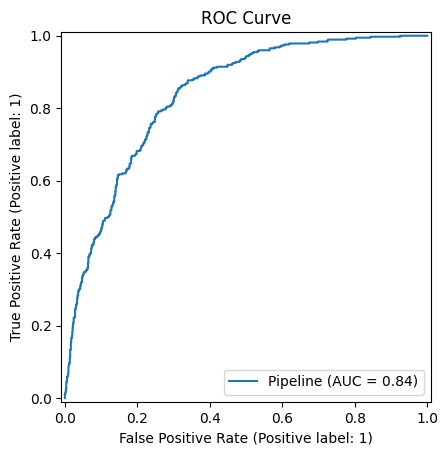

PR AUC: 0.61930514554387


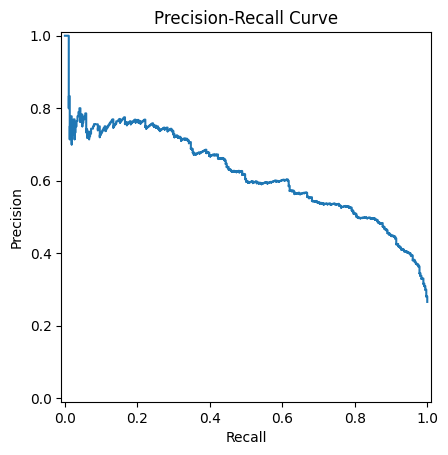

In [10]:
# Evaluate on test set
model = joblib.load(os.path.join(ARTIFACTS_DIR, 'pipeline.joblib'))
y_pred = model.predict(X_test)
y_proba = None
try:
    y_proba = model.predict_proba(X_test)[:,1]
except Exception:
    pass

print('\n--- Classification report ---')
print(classification_report(y_test, y_pred))

# Confusion matrix
cm = confusion_matrix(y_test, y_pred)
print('\nConfusion matrix:')
print(cm)

# ROC AUC if probabilities available
if y_proba is not None:
    roc = roc_auc_score(y_test, y_proba)
    print('\nROC AUC:', roc)
    RocCurveDisplay.from_estimator(model, X_test, y_test)
    plt.title('ROC Curve')
    plt.show()

# Precision-Recall curve
if y_proba is not None:
    precision, recall, _ = precision_recall_curve(y_test, y_proba)
    pr_auc = auc(recall, precision)
    print('PR AUC:', pr_auc)
    PrecisionRecallDisplay(precision=precision, recall=recall).plot()
    plt.title('Precision-Recall Curve')
    plt.show()


,0
Contract_Month-to-month,0.216443
InternetService_Fiber optic,0.054124
OnlineSecurity_No,0.032388
customerID_8627-EHGIP,0.022712
gender_Male,0.022705
customerID_0378-XSZPU,0.018415
DeviceProtection_Yes,0.017496
PaperlessBilling_Yes,0.016597
PaymentMethod_Electronic check,0.015762
customerID_6323-AYBRX,0.014667


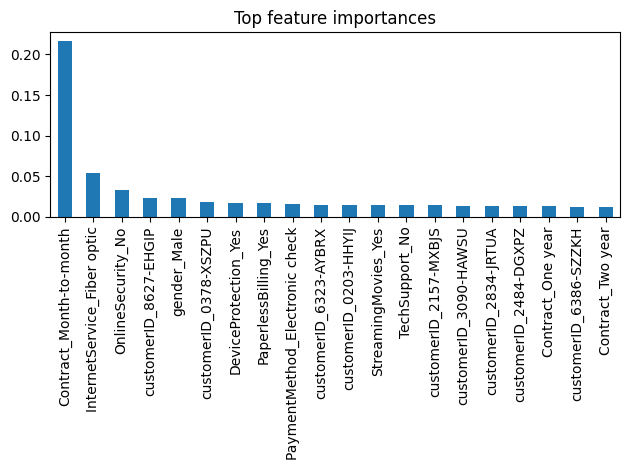

In [11]:
# Feature importance (model dependent)
try:
    # If pipeline contains a preprocessor and classifier with feature_importances_
    clf = model.named_steps.get('clf', None)
    prep = model.named_steps.get('preprocessor', None)
    if clf is None and hasattr(model, 'steps'):
        # handle imblearn pipeline where named_steps may be available differently
        try:
            clf = model.steps[-1][1]
            prep = model.named_steps.get('preprocessor', None)
        except Exception:
            clf = None

    if clf is not None and hasattr(clf, 'feature_importances_'):
        import numpy as np
        fi = clf.feature_importances_
        # build feature names from preprocessor
        cat_features = categorical_features
        num_features = numeric_features
        # expand onehot feature names if encoder exists
        feature_names = []
        if prep is not None:
            try:
                # transform sample to get output feature count
                ohe = prep.named_transformers_['cat'].named_steps['onehot']
                ohe_features = ohe.get_feature_names_out(cat_features).tolist()
                feature_names = num_features + ohe_features
            except Exception:
                feature_names = num_features + cat_features
        else:
            feature_names = num_features + cat_features

        fi_series = pd.Series(fi, index=feature_names).sort_values(ascending=False).head(20)
        display(fi_series)
        fi_series.plot.bar()
        plt.title('Top feature importances')
        plt.tight_layout()
        plt.show()
    else:
        print('No feature_importances_ attribute available for classifier. Consider using SHAP for model-agnostic explainability.')
except Exception as e:
    print('Feature importance step failed:', e)


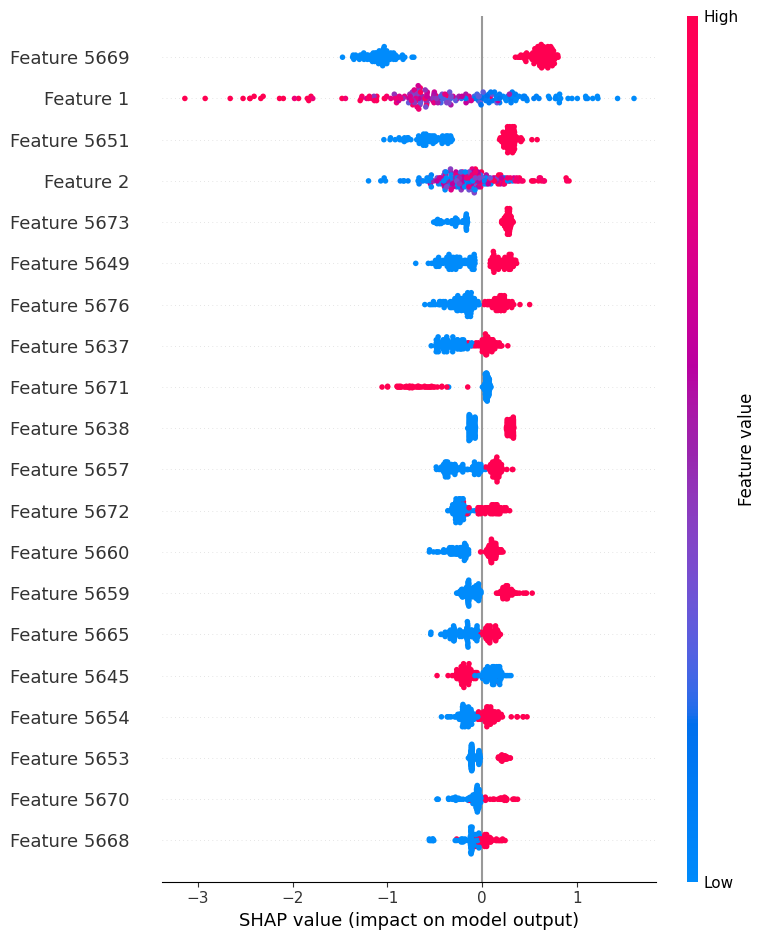

In [12]:
# SHAP explainability (optional). This may be slow on large datasets.
try:
    import shap
    explainer = None
    clf = model.named_steps.get('clf', None)
    prep = model.named_steps.get('preprocessor', None)
    # prepare a small sample for SHAP
    X_sample = X_test.sample(n=min(200, len(X_test)), random_state=RANDOM_STATE)
    X_sample_trans = prep.transform(X_sample)
    if 'XGB' in clf.__class__.__name__ or 'XGB' in str(type(clf)):
        explainer = shap.TreeExplainer(clf)
    elif hasattr(clf, 'predict_proba') or hasattr(clf, 'decision_function'):
        try:
            explainer = shap.Explainer(clf, X_sample_trans)
        except Exception:
            explainer = None

    if explainer is not None:
        shap_values = explainer(X_sample_trans)
        shap.summary_plot(shap_values, X_sample_trans, feature_names=None, show=True)
    else:
        print('Could not build SHAP explainer for this model automatically.')
except Exception as e:
    print('SHAP not run (library missing or failed):', e)


## Next steps & Production checklist

- Move preprocessing + model into a Python package or script for easier deployment.  
- Add unit tests around preprocessing and predict functions.  
- Add experiment tracking (MLflow, Weights & Biases).  
- Create reproducible environment with `requirements.txt` and pin versions.  
- Add CI to run basic smoke tests on the pipeline.  
- Consider model monitoring to detect data drift in production.
